In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import ttest_ind

In [44]:
df = pd.read_csv("StudentsPerformance.csv")
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [45]:
#Understand the dataset
df.shape

(1000, 8)

In [46]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


In [47]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [48]:
#DATA CLEANING AND PROCESSING
#checking missing values and duplicates
df.isnull().sum()

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

In [49]:
df = df.dropna()

In [50]:
df.duplicated().sum()
df = df.drop_duplicates()

In [51]:
df['Average'] = (df['math score'] + df['reading score'] + df['writing score']) / 3

df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,Average
0,female,group B,bachelor's degree,standard,none,72,72,74,72.666667
1,female,group C,some college,standard,completed,69,90,88,82.333333
2,female,group B,master's degree,standard,none,90,95,93,92.666667
3,male,group A,associate's degree,free/reduced,none,47,57,44,49.333333
4,male,group C,some college,standard,none,76,78,75,76.333333


In [52]:
#Handle inconsistent data
df.columns = df.columns.str.strip()
for col in df.select_dtypes(include='str').columns:
    df[col] = df[col].str.strip().str.lower()

In [53]:
#checked cleaned data
df.isnull().sum()

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
Average                        0
dtype: int64

In [54]:
#Create average marks
df['Average'] = df[['math score', 'reading score', 'writing score']].mean(axis=1)

In [55]:
df[['math score', 'reading score', 'writing score']].mean()

math score       66.089
reading score    69.169
writing score    68.054
dtype: float64

In [56]:
df['Average'].max(), df['Average'].min()

(np.float64(100.0), np.float64(9.0))

In [57]:
df['Performance'] = pd.cut(df['Average'], bins=[-1, 40, 60, 80, 100],
labels=['Poor', 'Average', 'Good', 'Excellent'])

df['Performance'].value_counts()

Performance
Good         513
Average      261
Excellent    194
Poor          32
Name: count, dtype: int64

In [58]:
#Correlation
df[['math score', 'reading score', 'writing score']].corr()

,math score,reading score,writing score
math score,1.000000,0.817580,0.802642
reading score,0.817580,1.000000,0.954598
writing score,0.802642,0.954598,1.000000


In [71]:
#Covariance – Relationship between subject marks
covariance = df[['math score', 'reading score', 'writing score']].cov()

covariance

,math score,reading score,writing score
math score,229.918998,180.998958,184.939133
reading score,180.998958,213.165605,211.786661
writing score,184.939133,211.786661,230.907992


In [72]:
#Correlation – Relationship between subject marks
correlation = df[['math score', 'reading score', 'writing score']].corr()

correlation

,math score,reading score,writing score
math score,1.000000,0.817580,0.802642
reading score,0.817580,1.000000,0.954598
writing score,0.802642,0.954598,1.000000


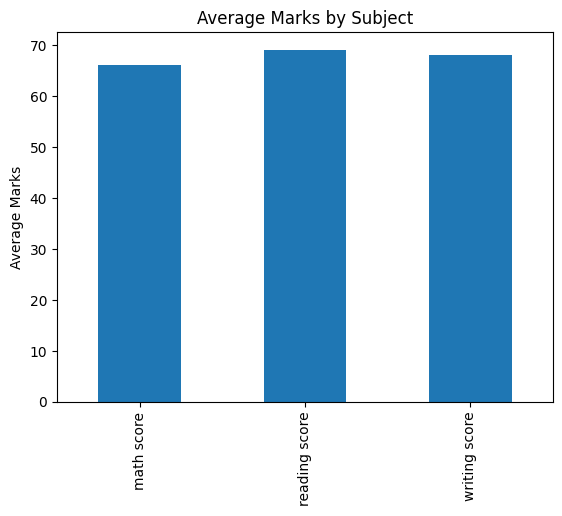

In [59]:
df[['math score', 'reading score', 'writing score']].mean().plot(kind='bar')

plt.title("Average Marks by Subject")
plt.ylabel("Average Marks")
plt.show()

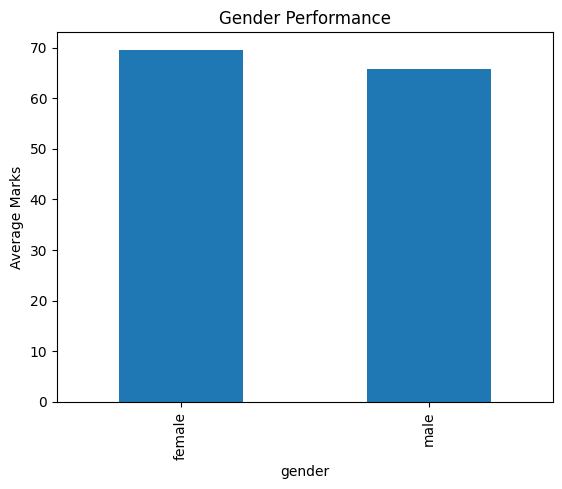

In [60]:
df.groupby('gender')['Average'].mean().plot(kind='bar')

plt.title("Gender Performance")
plt.ylabel("Average Marks")
plt.show()

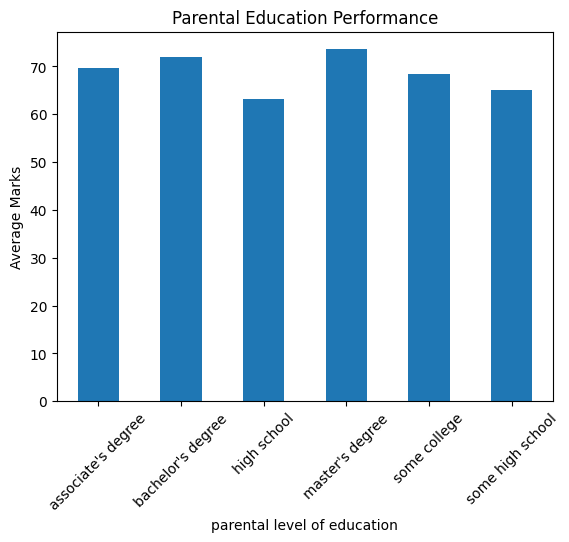

In [61]:
df.groupby('parental level of education')['Average'].mean().plot(kind='bar')

plt.title("Parental Education Performance")
plt.xticks(rotation=45)
plt.ylabel("Average Marks")
plt.show()

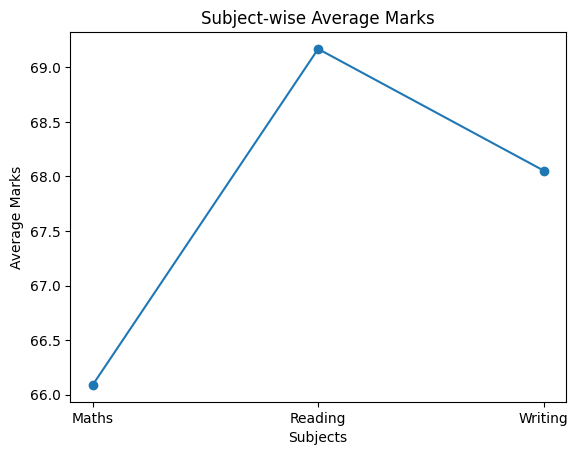

In [73]:
#Line graph – Subject-wise average marks
subjects = ['Maths', 'Reading', 'Writing']
marks = df[['math score', 'reading score', 'writing score']].mean()

plt.plot(subjects, marks, marker='o')

plt.title("Subject-wise Average Marks")
plt.xlabel("Subjects")
plt.ylabel("Average Marks")
plt.show()

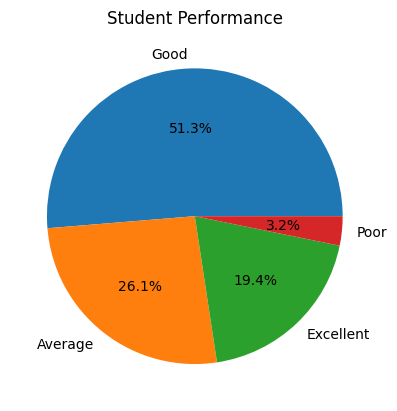

In [74]:
#Pie chart – Student performance
df['Performance'].value_counts().plot(
    kind='pie', autopct='%1.1f%%'
)

plt.title("Student Performance")
plt.ylabel("")
plt.show()

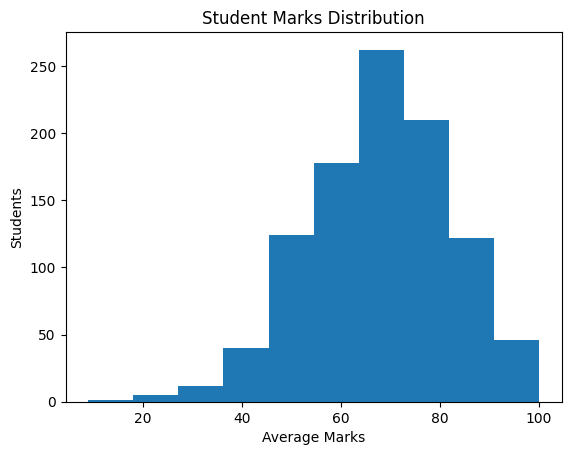

In [76]:
#Histogram – Marks distribution
plt.hist(df['Average'], bins=10)
plt.title("Student Marks Distribution")
plt.xlabel("Average Marks")
plt.ylabel("Students")
plt.show()

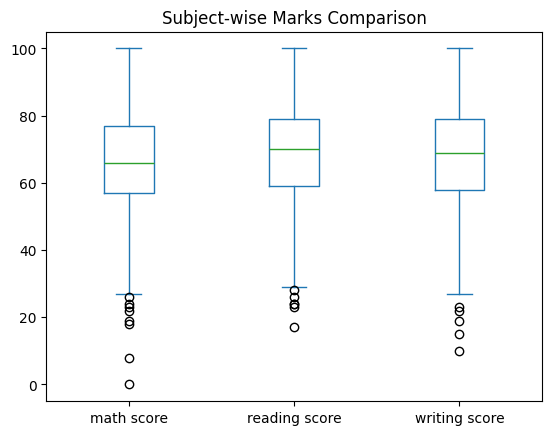

In [82]:
#Box plot – Subject comparison
df[['math score', 'reading score', 'writing score']].plot(kind='box')

plt.title("Subject-wise Marks Comparison")
plt.show()

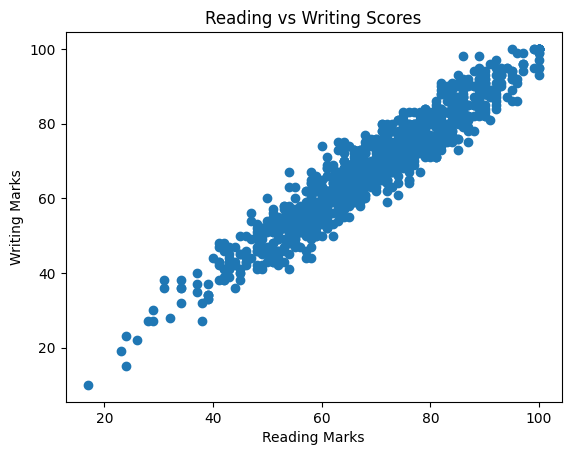

In [83]:
#Scatter plot – Reading vs Writing
plt.scatter(df['reading score'], df['writing score'])

plt.title("Reading vs Writing Scores")
plt.xlabel("Reading Marks")
plt.ylabel("Writing Marks")
plt.savefig("Scatter_Plot.png")
plt.show()

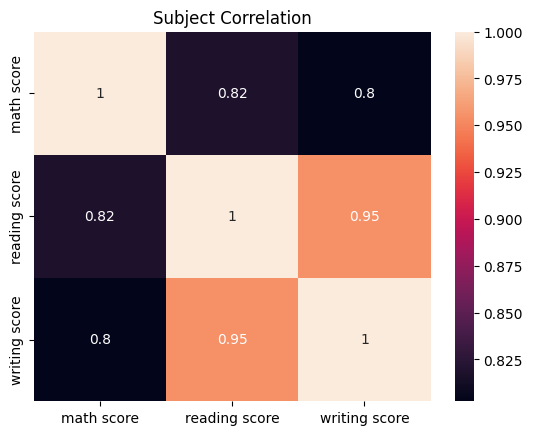

In [84]:
#Heatmap – Subject correlation
sns.heatmap(df[['math score', 'reading score', 'writing score']].corr(), annot=True)

plt.title("Subject Correlation")
plt.savefig("Heatmap.png")
plt.show()

In [66]:
#Hypothesis t-testing
a = df[df['test preparation course'] == 'completed']['math score']

b = df[df['test preparation course'] == 'none']['math score']

t, p = ttest_ind(a, b)

print("T-statistic:", t)
print("P-value:", p)

if p < 0.05:
    print("Reject Null Hypothesis")
else:
    print("Fail to Reject Null Hypothesis")

T-statistic: 5.704616417349102
P-value: 1.5359134607147448e-08
Reject Null Hypothesis


In [87]:
print("Average Subject Marks:")
df[['math score', 'reading score', 'writing score']].mean()

print("Gender Performance:")
df.groupby('gender')['Average'].mean()

print("Test Preparation Performance:")
df.groupby('test preparation course')['Average'].mean()

print("Lunch Performance:")
df.groupby('lunch')['Average'].mean()

print("Parental Education Performance:")
df.groupby('parental level of education')['Average'].mean()

Average Subject Marks:
Gender Performance:
Test Preparation Performance:
Lunch Performance:
Parental Education Performance:


parental level of education
associate's degree    69.569069
bachelor's degree     71.923729
high school           63.096939
master's degree       73.598870
some college          68.476401
some high school      65.108007
Name: Average, dtype: float64

In [88]:
df.to_csv("Cleaned_Student_Data.csv", index=False)

In [89]:
df.describe().to_csv("Analysis_Results.csv")

In [90]:
df[['math score', 'reading score', 'writing score']].cov().to_csv("Covariance.csv")

df[['math score', 'reading score', 'writing score']].corr().to_csv("Correlation.csv")